Available GPUs: []
Mounted at /content/drive
Found Train File: /content/drive/MyDrive/MIT-BIH Arrhythmia/mitbih_train.csv
Found Test File:  /content/drive/MyDrive/MIT-BIH Arrhythmia/mitbih_test.csv

Missing values in Train: 0
Missing values in Test:  0

--- Dataset Distribution (Total: 109,446 beats) ---
Class 0 [N (Normal)]: 90589 samples (82.77%)
Class 1 [SVEB]: 2779 samples (2.54%)
Class 2 [VEB]: 7236 samples (6.61%)
Class 3 [F (Fusion)]: 803 samples (0.73%)
Class 4 [Q (Unknown)]: 8039 samples (7.35%)

Normalization Range -> Min: 0.00, Max: 1.00
Final Tensor Shapes -> Train: (78798, 187, 1), Val: (8756, 187, 1), Test: (21892, 187, 1)
Class Weights: {0: np.float64(0.24), 1: np.float64(7.88), 2: np.float64(3.03), 3: np.float64(27.31), 4: np.float64(2.72)}


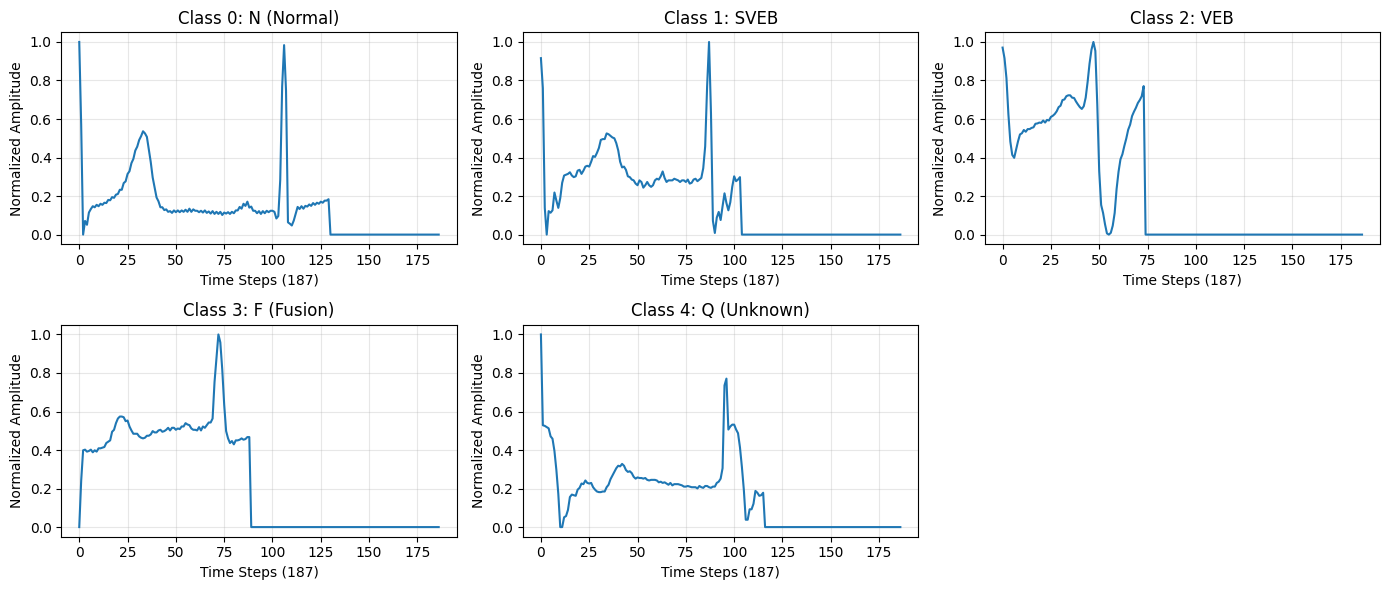

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# 0. التأكد من تفعيل كارت الشاشة (GPU)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

# 1. ربط Google Drive (هتظهرلك نافذة توافق فيها على الصلاحيات)
from google.colab import drive
drive.mount('/content/drive')

# البحث التلقائي عن ملفات الداتا جوا Google Drive
def find_file(filename, search_path='/content/drive/MyDrive'):
    for root, dirs, files in os.walk(search_path):
        if filename in files:
            return os.path.join(root, filename)
    return None

train_path = find_file('mitbih_train.csv')
test_path  = find_file('mitbih_test.csv')

if train_path is None or test_path is None:
    raise FileNotFoundError("تأكد إن ملفات mitbih_train.csv و mitbih_test.csv مرفوعة جوا MyDrive!")

print("Found Train File:", train_path)
print("Found Test File: ", test_path)

# قراءة البيانات
train_df = pd.read_csv(train_path, header=None)
test_df  = pd.read_csv(test_path, header=None)

# 2. مرحلة التنظيف (Data Cleaning)
print("\nMissing values in Train:", train_df.isnull().sum().sum())
print("Missing values in Test: ", test_df.isnull().sum().sum())

train_df.replace([np.inf, -np.inf], np.nan, inplace=True)
test_df.replace([np.inf, -np.inf], np.nan, inplace=True)
train_df.dropna(inplace=True)
test_df.dropna(inplace=True)

# فصل الخصائص (187 نقطة) عن التصنيف (العمود الأخير)
X_train_full = train_df.iloc[:, :-1].values.astype(np.float32)
y_train_full = train_df.iloc[:, -1].values.astype(np.int32)

X_test = test_df.iloc[:, :-1].values.astype(np.float32)
y_test = test_df.iloc[:, -1].values.astype(np.int32)

# 3. استكشاف الفئات الخمس (EDA - حسب معيار AAMI)
class_names = ['N (Normal)', 'SVEB', 'VEB', 'F (Fusion)', 'Q (Unknown)']
total_y = np.concatenate([y_train_full, y_test])
unique, counts = np.unique(total_y, return_counts=True)

print("\n--- Dataset Distribution (Total: 109,446 beats) ---")
for cls, cnt in zip(unique, counts):
    print(f"Class {cls} [{class_names[cls]}]: {cnt} samples ({cnt/len(total_y)*100:.2f}%)")

# 4. تقسيم البيانات (Stratified Train / Validation / Test Split)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.10,
    random_state=42,
    stratify=y_train_full
)

# 5. مرحلة التحويل (Transformation: Normalization Check + 3D Reshaping)
print(f"\nNormalization Range -> Min: {X_train.min():.2f}, Max: {X_train.max():.2f}")

X_train_3d = np.expand_dims(X_train, axis=-1)
X_val_3d   = np.expand_dims(X_val, axis=-1)
X_test_3d  = np.expand_dims(X_test, axis=-1)

print(f"Final Tensor Shapes -> Train: {X_train_3d.shape}, Val: {X_val_3d.shape}, Test: {X_test_3d.shape}")

# حساب أوزان الفئات (Class Weights) لتجربة تحسين الفئات النادرة لاحقاً
weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(weights))
print("Class Weights:", {k: round(v, 2) for k, v in class_weight_dict.items()})

# 6. رسم عينة من كل فئة (احفظ الصورة دي للتقرير والبرزنتيشن)
plt.figure(figsize=(14, 6))
for i in range(5):
    idx = np.where(y_train == i)[0][0]
    plt.subplot(2, 3, i + 1)
    plt.plot(X_train[idx], color='#1f77b4', linewidth=1.5)
    plt.title(f"Class {i}: {class_names[i]}")
    plt.xlabel("Time Steps (187)")
    plt.ylabel("Normalized Amplitude")
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

=== Encoder Summary (Matches Table 2) ===


Model: "CAE_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input (InputLayer)              │ (None, 187, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_Enc1 (Conv1D)            │ (None, 187, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN_Enc1 (BatchNormalization)    │ (None, 187, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool_Enc1 (MaxPooling1D)     │ (None, 94, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_Enc2 (Conv1D)            │ (None, 94, 32)         │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN_Enc2 (BatchNormalization)    │ (None, 94, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool_Enc2 (MaxPooling1D)     │ (None, 47, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_Enc3 (Conv1D)            │ (None, 47, 16)         │         1,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BN_Enc3 (BatchNormalization)    │ (None, 47, 16)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool_Enc3 (MaxPooling1D)     │ (None, 24, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Bottleneck_32 (Dense)           │ (None, 32)             │        12,320 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,752 (81.06 KB)

 Trainable params: 20,528 (80.19 KB)

 Non-trainable params: 224 (896.00 B)

... (3 outputs left out)

 Total params: 21,809 (85.19 KB)

 Trainable params: 21,617 (84.44 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 106s 163ms/step - loss: 0.0119 - val_loss: 0.0095
Epoch 2/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 139s 159ms/step - loss: 0.0029 - val_loss: 0.0024
Epoch 3/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 142s 159ms/step - loss: 0.0022 - val_loss: 0.0020
Epoch 4/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 142s 160ms/step - loss: 0.0018 - val_loss: 0.0017
Epoch 5/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 142s 159ms/step - loss: 0.0016 - val_loss: 0.0023
Epoch 6/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 99s 160ms/step - loss: 0.0014 - val_loss: 0.0014
Epoch 7/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 141s 158ms/step - loss: 0.0013 - val_loss: 0.0012
Epoch 8/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 97s 158ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 9/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 143s 160ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 10/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 99s 160ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 11/100
616/616 ━━━━━━━━━━━━━━━━━━━━ 98s 159ms/step - loss: 0.0010 - val_loss: 0.0010
E

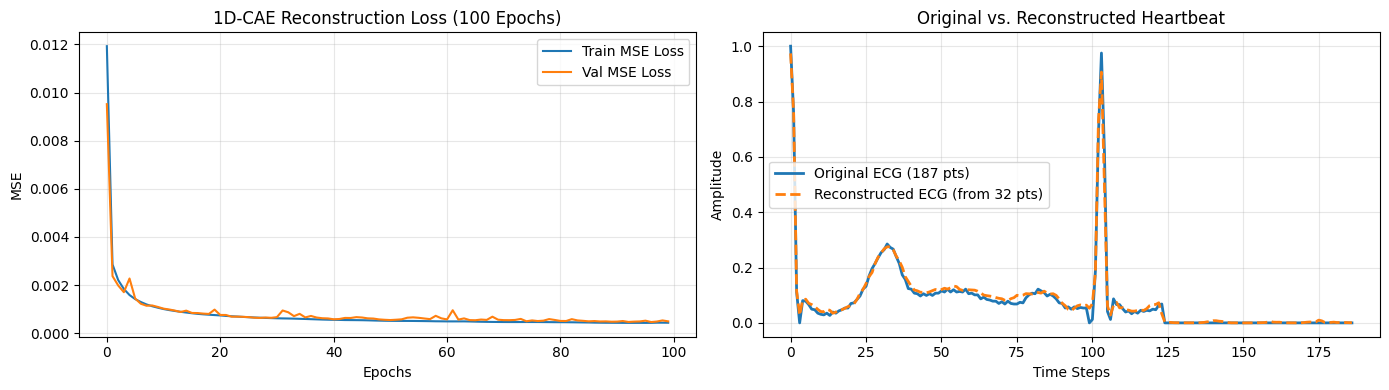

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# تثبيت البذرة العشوائية لضمان ثبات النتائج
tf.random.set_seed(42)
np.random.seed(42)

# ==========================================
# 1. بناء الـ Encoder (طبقات 0 إلى 11 في Table 2)
# ==========================================
encoder_input = layers.Input(shape=(187, 1), name="Input")

# Block 1: (187, 1) -> (94, 64)
x = layers.Conv1D(64, kernel_size=3, activation='relu', padding='same', name="Conv1D_Enc1")(encoder_input)
x = layers.BatchNormalization(name="BN_Enc1")(x)
x = layers.MaxPooling1D(pool_size=2, padding='same', name="MaxPool_Enc1")(x)

# Block 2: (94, 64) -> (47, 32)
x = layers.Conv1D(32, kernel_size=3, activation='relu', padding='same', name="Conv1D_Enc2")(x)
x = layers.BatchNormalization(name="BN_Enc2")(x)
x = layers.MaxPooling1D(pool_size=2, padding='same', name="MaxPool_Enc2")(x)

# Block 3: (47, 32) -> (24, 16)
x = layers.Conv1D(16, kernel_size=3, activation='relu', padding='same', name="Conv1D_Enc3")(x)
x = layers.BatchNormalization(name="BN_Enc3")(x)
x = layers.MaxPooling1D(pool_size=2, padding='same', name="MaxPool_Enc3")(x)

# Bottleneck: (24, 16) -> (384,) -> (32,)
x = layers.Flatten(name="Flatten")(x)
encoded_output = layers.Dense(32, activation='relu', name="Bottleneck_32")(x)

encoder = models.Model(encoder_input, encoded_output, name="CAE_Encoder")

# ==========================================
# 2. بناء الـ Decoder (طبقات 12 إلى 23 في Table 2)
# ==========================================
decoder_input = layers.Input(shape=(32,), name="Latent_Input")

d = layers.Dense(384, activation='relu', name="Dense_Dec")(decoder_input)
d = layers.Reshape((24, 16), name="Reshape_Dec")(d)

# Block 1: (24, 16) -> (48, 16)
d = layers.Conv1D(16, kernel_size=3, activation='relu', padding='same', name="Conv1D_Dec1")(d)
d = layers.UpSampling1D(size=2, name="UpSample_Dec1")(d)

# Block 2: (48, 16) -> (96, 32)
d = layers.Conv1D(32, kernel_size=3, activation='relu', padding='same', name="Conv1D_Dec2")(d)
d = layers.BatchNormalization(name="BN_Dec1")(d)
d = layers.UpSampling1D(size=2, name="UpSample_Dec2")(d)

# Block 3: (96, 32) -> (192, 64)
d = layers.Conv1D(64, kernel_size=3, activation='relu', padding='same', name="Conv1D_Dec3")(d)
d = layers.BatchNormalization(name="BN_Dec2")(d)
d = layers.UpSampling1D(size=2, name="UpSample_Dec3")(d)

# Cropping & Output: (192, 64) -> (187, 64) -> (187, 1)
d = layers.Cropping1D(cropping=(0, 5), name="Cropping1D")(d)
decoded_output = layers.Conv1D(1, kernel_size=3, activation='sigmoid', padding='same', name="Output_Signal")(d)

decoder = models.Model(decoder_input, decoded_output, name="CAE_Decoder")

# تجميع الـ Autoencoder الكامل
autoencoder_output = decoder(encoder(encoder_input))
autoencoder = models.Model(encoder_input, autoencoder_output, name="1D_CAE_Full")

print("=== Encoder Summary (Matches Table 2) ===")
encoder.summary()
print("\n=== Decoder Summary (Matches Table 2) ===")
decoder.summary()

# ==========================================
# 3. تدريب الـ Autoencoder (100 Epochs, Adam lr=1e-3, MSE)
# ==========================================
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse'
)

start_time = time.time()
history_cae = autoencoder.fit(
    X_train_3d, X_train_3d,
    epochs=100,
    batch_size=128,
    validation_data=(X_val_3d, X_val_3d),
    verbose=1
)
cae_train_time = time.time() - start_time
print(f"\nCAE Training Time: {cae_train_time:.2f} seconds")

# ==========================================
# 4. حساب مقاييس جودة الضغط ومقارنتها بـ Table 4 في البيبر
# ==========================================
X_test_reconstructed = autoencoder.predict(X_test_3d, batch_size=256, verbose=0)

orig = X_test_3d.squeeze()          # (21892, 187)
recon = X_test_reconstructed.squeeze() # (21892, 187)

# المعادلات (11), (12), (13), (14) من البيبر
cr = 187.0 / 32.0
rmse = np.sqrt(np.mean((orig - recon) ** 2))
prd = (np.sqrt(np.sum((orig - recon) ** 2)) / np.sqrt(np.sum(orig ** 2))) * 100.0
qs = cr / prd

print("\n" + "="*55)
print("   CAE Compression Metrics vs. Paper (Table 4)")
print("="*55)
print(f"{'Metric':<25} | {'Your Result':<12} | {'Paper (Table 4)':<12}")
print("-"*55)
print(f"{'Compression Ratio (CR)':<25} | {cr:<12.2f} | {'5.84':<12}")
print(f"{'RMSE':<25} | {rmse:<12.4f} | {'0.0361':<12}")
print(f"{'PRD (%)':<25} | {prd:<12.2f} | {'12.70':<12}")
print(f"{'Quality Score (QS)':<25} | {qs:<12.4f} | {'0.4602':<12}")
print("="*55)

# ==========================================
# 5. استخراج الميزات المضغوطة (32-dim) جاهزة للمرحلة الثانية
# ==========================================
X_train_encoded = encoder.predict(X_train_3d, batch_size=256, verbose=0)
X_val_encoded   = encoder.predict(X_val_3d, batch_size=256, verbose=0)
X_test_encoded  = encoder.predict(X_test_3d, batch_size=256, verbose=0)

print(f"\nEncoded Latent Shapes -> Train: {X_train_encoded.shape}, Val: {X_val_encoded.shape}, Test: {X_test_encoded.shape}")

# حفظ الـ Encoder والـ Autoencoder على Drive للأمان
encoder.save('/content/drive/MyDrive/cae_encoder.keras')
autoencoder.save('/content/drive/MyDrive/cae_full.keras')

# رسم منحنى الخسارة ومثال للإشارة الأصلية vs المعاد بناؤها (للتقرير)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history_cae.history['loss'], label='Train MSE Loss')
axes[0].plot(history_cae.history['val_loss'], label='Val MSE Loss')
axes[0].set_title('1D-CAE Reconstruction Loss (100 Epochs)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('MSE')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(orig[0], label='Original ECG (187 pts)', linewidth=2)
axes[1].plot(recon[0], '--', label='Reconstructed ECG (from 32 pts)', linewidth=2)
axes[1].set_title('Original vs. Reconstructed Heartbeat')
axes[1].set_xlabel('Time Steps')
axes[1].set_ylabel('Amplitude')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Active GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Loading data and saved CAE Encoder from Google Drive...
Mounted at /content/drive
Successfully loaded encoded features from saved CAE Encoder!
Classifier Input Shapes -> Train: (78798, 32, 1), Val: (8756, 32, 1), Test: (21892, 32, 1)


Model: "BiLSTM_MHA_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Latent_Sequence_In… │ (None, 32, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BiLSTM_128          │ (None, 32, 256)   │    133,120 │ Latent_Sequence_… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout_BiLSTM1     │ (None, 32, 256)   │          0 │ BiLSTM_128[0][0]  │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BiLSTM_64           │ (None, 32, 128)   │    164,352 │ Dropout_BiLSTM1[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout_BiLSTM2     │ (None, 32, 128)   │          0 │ BiLSTM_64[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MultiHead_Attentio… │ (None, 32, 128)   │    263,808 │ Dropout_BiLSTM2[… │
│ (MultiHeadAttentio… │                   │            │ Dropout_BiLSTM2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Residual_Connection │ (None, 32, 128)   │          0 │ Dropout_BiLSTM2[… │
│ (Add)               │                   │            │ MultiHead_Attent… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Layer_Norm          │ (None, 32, 128)   │        256 │ Residual_Connect… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Flatten_Attn        │ (None, 4096)      │          0 │ Layer_Norm[0][0]  │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dense_128 (Dense)   │ (None, 128)       │    524,416 │ Flatten_Attn[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout_Dense       │ (None, 128)       │          0 │ Dense_128[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dense_64 (Dense)    │ (None, 64)        │      8,256 │ Dropout_Dense[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Output_Softmax      │ (None, 5)         │        325 │ Dense_64[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,094,533 (4.18 MB)

 Trainable params: 1,094,533 (4.18 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
616/616 ━━━━━━━━━━━━━━━━━━━━ 25s 24ms/step - accuracy: 0.8925 - loss: 0.3835 - val_accuracy: 0.9567 - val_loss: 0.1583
Epoch 2/200
616/616 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.9540 - loss: 0.1681 - val_accuracy: 0.9665 - val_loss: 0.1134
Epoch 3/200
616/616 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.9632 - loss: 0.1312 - val_accuracy: 0.9712 - val_loss: 0.0965
Epoch 4/200
616/616 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.9678 - loss: 0.1132 - val_accuracy: 0.9742 - val_loss: 0.0890
Epoch 5/200
616/616 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.9710 - loss: 0.1014 - val_accuracy: 0.9736 - val_loss: 0.0857
Epoch 6/200
616/616 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.9731 - loss: 0.0923 - val_accuracy: 0.9770 - val_loss: 0.0809
Epoch 7/200
616/616 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.9733 - loss: 0.0875 - val_accuracy: 0.9766 - val_loss: 0.0812
Epoch 8/200
616/616 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.9763 - loss: 0

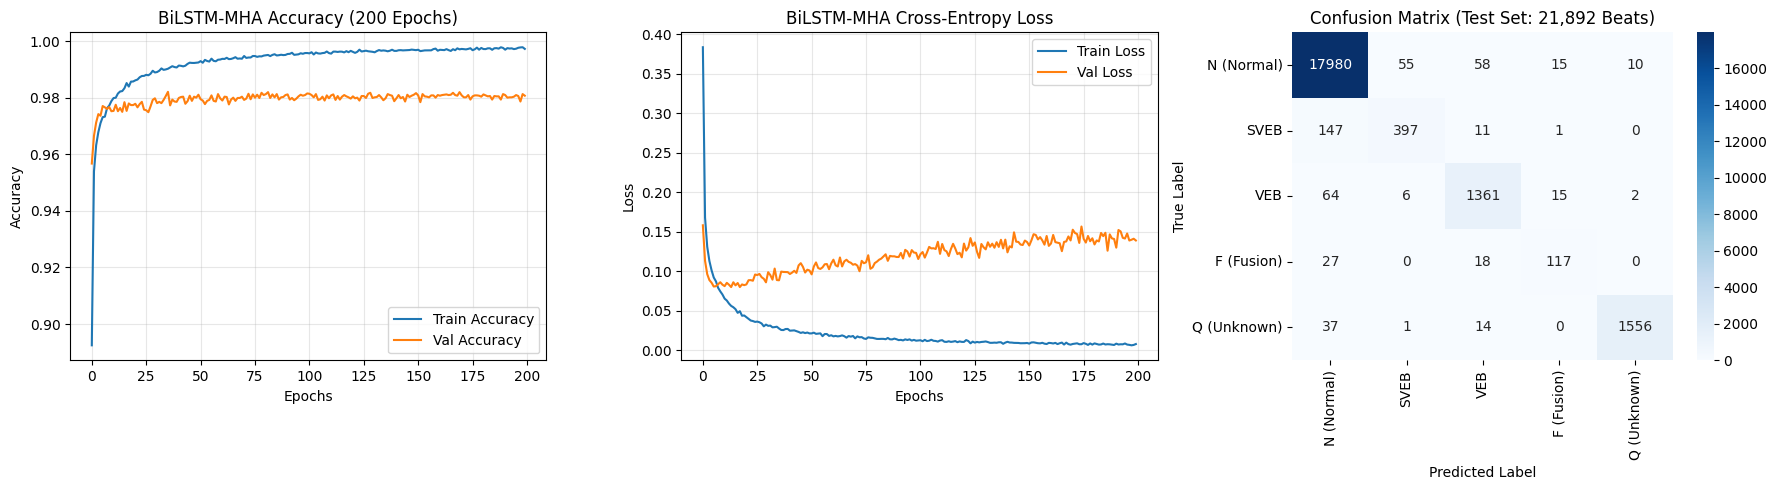

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# 0. التأكد من تفعيل T4 GPU
gpus = tf.config.list_physical_devices('GPU')
print("Active GPUs:", gpus)
if not gpus:
    print("تنبيه: يفضل تفعيل T4 GPU من قائمة Runtime لتسريع الـ 200 Epoch!")

tf.random.set_seed(42)
np.random.seed(42)

# ==========================================
# 1. استرجاع البيانات والـ Encoder المحفوظ تلقائياً (لو الذاكرة اتصفرت بعد تغيير الـ GPU)
# ==========================================
if 'X_train_encoded' not in globals():
    print("Loading data and saved CAE Encoder from Google Drive...")
    from google.colab import drive
    drive.mount('/content/drive')

    def find_file(filename, search_path='/content/drive/MyDrive'):
        for root, dirs, files in os.walk(search_path):
            if filename in files:
                return os.path.join(root, filename)
        return None

    train_path = find_file('mitbih_train.csv')
    test_path  = find_file('mitbih_test.csv')
    encoder_path = '/content/drive/MyDrive/cae_encoder.keras'

    train_df = pd.read_csv(train_path, header=None).replace([np.inf, -np.inf], np.nan).dropna()
    test_df  = pd.read_csv(test_path, header=None).replace([np.inf, -np.inf], np.nan).dropna()

    X_train_full = train_df.iloc[:, :-1].values.astype(np.float32)
    y_train_full = train_df.iloc[:, -1].values.astype(np.int32)
    X_test = test_df.iloc[:, :-1].values.astype(np.float32)
    y_test = test_df.iloc[:, -1].values.astype(np.int32)

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.10, random_state=42, stratify=y_train_full
    )

    X_train_3d = np.expand_dims(X_train, axis=-1)
    X_val_3d   = np.expand_dims(X_val, axis=-1)
    X_test_3d  = np.expand_dims(X_test, axis=-1)

    encoder = tf.keras.models.load_model(encoder_path)
    X_train_encoded = encoder.predict(X_train_3d, batch_size=256, verbose=0)
    X_val_encoded   = encoder.predict(X_val_3d, batch_size=256, verbose=0)
    X_test_encoded  = encoder.predict(X_test_3d, batch_size=256, verbose=0)
    print("Successfully loaded encoded features from saved CAE Encoder!")

# إعادة تشكيل الميزات المضغوطة من (N, 32) إلى (N, 32, 1) لتناسب طبقات BiLSTM
X_train_seq = np.expand_dims(X_train_encoded, axis=-1)
X_val_seq   = np.expand_dims(X_val_encoded, axis=-1)
X_test_seq  = np.expand_dims(X_test_encoded, axis=-1)

print(f"Classifier Input Shapes -> Train: {X_train_seq.shape}, Val: {X_val_seq.shape}, Test: {X_test_seq.shape}")

# ==========================================
# 2. بناء مصنف BiLSTM + Multi-Head Attention (مطابق لـ Table 3)
# ==========================================
def build_bilstm_attention_classifier(seq_len=32, num_classes=5):
    inputs = layers.Input(shape=(seq_len, 1), name="Latent_Sequence_Input")

    # Stacked BiLSTM Layers (128 then 64 units + Dropout 0.3)
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True), name="BiLSTM_128")(inputs)
    x = layers.Dropout(0.3, name="Dropout_BiLSTM1")(x)

    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True), name="BiLSTM_64")(x)
    x = layers.Dropout(0.3, name="Dropout_BiLSTM2")(x)

    # Multi-Head Self-Attention (8 Heads, Key Dim = 64) + Residual + LayerNorm
    attn_output = layers.MultiHeadAttention(
        num_heads=8, key_dim=64, name="MultiHead_Attention_8H"
    )(x, x)
    x = layers.Add(name="Residual_Connection")([x, attn_output])
    x = layers.LayerNormalization(name="Layer_Norm")(x)

    # Classification Head (Flatten -> Dense 128 -> Dropout 0.1 -> Dense 64 -> Softmax 5)
    x = layers.Flatten(name="Flatten_Attn")(x)
    x = layers.Dense(128, activation='relu', name="Dense_128")(x)
    x = layers.Dropout(0.1, name="Dropout_Dense")(x)
    x = layers.Dense(64, activation='relu', name="Dense_64")(x)
    outputs = layers.Dense(num_classes, activation='softmax', name="Output_Softmax")(x)

    model = models.Model(inputs, outputs, name="BiLSTM_MHA_Classifier")
    return model

classifier = build_bilstm_attention_classifier(seq_len=32, num_classes=5)
classifier.summary()

# ==========================================
# 3. تدريب المصنف (200 Epochs, Adam lr=0.001, Batch=128)
# ==========================================
classifier.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# حفظ أفضل نسخة بناءً على دقة الـ Validation
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    '/content/drive/MyDrive/bilstm_mha_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=0
)

start_time = time.time()
history_clf = classifier.fit(
    X_train_seq, y_train,
    epochs=200,
    batch_size=128,
    validation_data=(X_val_seq, y_val),
    callbacks=[checkpoint_cb],
    verbose=1
)
clf_train_time = time.time() - start_time
print(f"\nClassifier Training Time (200 Epochs): {clf_train_time:.2f} seconds")

# تحميل أفضل وزن وصل له الموديل للتقييم النهائي
best_classifier = tf.keras.models.load_model('/content/drive/MyDrive/bilstm_mha_best.keras')

# ==========================================
# 4. التقييم ومقارنة المقاييس الخمسة بـ Table 5 و Table 6 في البيبر
# ==========================================
infer_start = time.time()
y_pred_probs = best_classifier.predict(X_test_seq, batch_size=256, verbose=0)
infer_time_ms = ((time.time() - infer_start) / len(X_test_seq)) * 1000.0

y_pred = np.argmax(y_pred_probs, axis=1)

acc = accuracy_score(y_test, y_pred) * 100.0
prec = precision_score(y_test, y_pred, average='macro', zero_division=0) * 100.0
sens = recall_score(y_test, y_pred, average='macro', zero_division=0) * 100.0
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0) * 100.0

# حساب الـ Specificity لكل فئة ثم المتوسط (Macro Specificity)
cm = confusion_matrix(y_test, y_pred)
specificities = []
for i in range(5):
    tn = np.sum(cm) - (np.sum(cm[i, :]) + np.sum(cm[:, i]) - cm[i, i])
    fp = np.sum(cm[:, i]) - cm[i, i]
    specificities.append(tn / (tn + fp))
spec = np.mean(specificities) * 100.0

print("\n" + "="*60)
print("   Classification Metrics vs. Paper (Table 5)")
print("="*60)
print(f"{'Metric':<25} | {'Your Result':<14} | {'Paper (Table 5)':<14}")
print("-"*60)
print(f"{'Accuracy (%)':<25} | {acc:<14.2f} | {'98.57':<14}")
print(f"{'Precision (%)':<25} | {prec:<14.2f} | {'93.13':<14}")
print(f"{'Sensitivity / Recall (%)':<25} | {sens:<14.2f} | {'90.30':<14}")
print(f"{'Specificity (%)':<25} | {spec:<14.2f} | {'98.99':<14}")
print(f"{'F1-Score (%)':<25} | {f1:<14.2f} | {'91.66':<14}")
print("="*60)
print(f"Average Inference Time per Beat: {infer_time_ms:.4f} ms")

class_names = ['N (Normal)', 'SVEB', 'VEB', 'F (Fusion)', 'Q (Unknown)']
print("\n=== Per-Class Performance (Compare with Paper Table 6) ===")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

# رسم منحنيات التدريب والـ Confusion Matrix (للتقرير والبرزنتيشن)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history_clf.history['accuracy'], label='Train Accuracy')
axes[0].plot(history_clf.history['val_accuracy'], label='Val Accuracy')
axes[0].set_title('BiLSTM-MHA Accuracy (200 Epochs)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_clf.history['loss'], label='Train Loss')
axes[1].plot(history_clf.history['val_loss'], label='Val Loss')
axes[1].set_title('BiLSTM-MHA Cross-Entropy Loss')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[2])
axes[2].set_title('Confusion Matrix (Test Set: 21,892 Beats)')
axes[2].set_xlabel('Predicted Label')
axes[2].set_ylabel('True Label')

plt.tight_layout()
plt.show()

Smoothed Class Weights: {0: 0.492, 1: 2.806, 2: 1.739, 3: 5.226, 4: 1.65}
Epoch 1/120
616/616 ━━━━━━━━━━━━━━━━━━━━ 24s 26ms/step - accuracy: 0.8538 - loss: 0.5832 - val_accuracy: 0.9130 - val_loss: 0.2767 - learning_rate: 0.0010
Epoch 2/120
616/616 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.9231 - loss: 0.2839 - val_accuracy: 0.9451 - val_loss: 0.1916 - learning_rate: 0.0010
Epoch 3/120
616/616 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.9394 - loss: 0.2317 - val_accuracy: 0.9552 - val_loss: 0.1610 - learning_rate: 0.0010
Epoch 4/120
616/616 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.9459 - loss: 0.2027 - val_accuracy: 0.9495 - val_loss: 0.1626 - learning_rate: 0.0010
Epoch 5/120
616/616 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.9488 - loss: 0.1847 - val_accuracy: 0.9563 - val_loss: 0.1565 - learning_rate: 0.0010
Epoch 6/120
616/616 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.9536 - loss: 0.1685 - val_accuracy: 0.9582 - val_loss: 0.1375 - learning_rate: 0.0

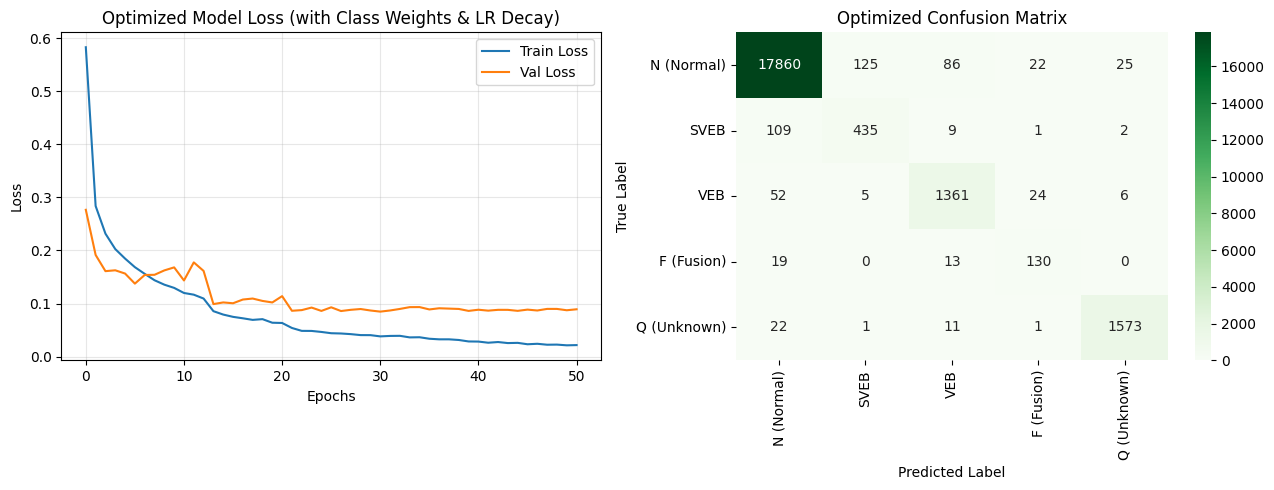

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

tf.random.set_seed(42)
np.random.seed(42)

# 1. التأكد من وجود البيانات المضغوطة في الذاكرة (أو تحميلها من Drive لو السيشن اتصفرت)
if 'X_train_seq' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    def find_file(filename, search_path='/content/drive/MyDrive'):
        for root, dirs, files in os.walk(search_path):
            if filename in files:
                return os.path.join(root, filename)
        return None

    train_df = pd.read_csv(find_file('mitbih_train.csv'), header=None).replace([np.inf, -np.inf], np.nan).dropna()
    test_df  = pd.read_csv(find_file('mitbih_test.csv'), header=None).replace([np.inf, -np.inf], np.nan).dropna()

    X_train_full = train_df.iloc[:, :-1].values.astype(np.float32)
    y_train_full = train_df.iloc[:, -1].values.astype(np.int32)
    X_test = test_df.iloc[:, :-1].values.astype(np.float32)
    y_test = test_df.iloc[:, -1].values.astype(np.int32)

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.10, random_state=42, stratify=y_train_full
    )

    encoder = tf.keras.models.load_model('/content/drive/MyDrive/cae_encoder.keras')
    X_train_seq = np.expand_dims(encoder.predict(np.expand_dims(X_train, -1), batch_size=256, verbose=0), -1)
    X_val_seq   = np.expand_dims(encoder.predict(np.expand_dims(X_val, -1), batch_size=256, verbose=0), -1)
    X_test_seq  = np.expand_dims(encoder.predict(np.expand_dims(X_test, -1), batch_size=256, verbose=0), -1)

# 2. حساب أوزان الفئات المتوازنة (Smoothed Class Weights) لمعالجة عدم التوازن
raw_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
smoothed_weights = np.sqrt(raw_weights)  # تنعيم الأوزان للحفاظ على توازن Precision و Recall
class_weight_dict = dict(enumerate(smoothed_weights))
print("Smoothed Class Weights:", {k: round(float(v), 3) for k, v in class_weight_dict.items()})

# 3. بناء نفس المعمارية الهجينة (BiLSTM + Multi-Head Attention)
def build_bilstm_attention_classifier(seq_len=32, num_classes=5):
    inputs = layers.Input(shape=(seq_len, 1))
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(inputs)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
    x = layers.Dropout(0.3)(x)

    attn_output = layers.MultiHeadAttention(num_heads=8, key_dim=64)(x, x)
    x = layers.Add()([x, attn_output])
    x = layers.LayerNormalization()(x)

    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.1)(x)
    x = layers.Dense(64, activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inputs, outputs, name="BiLSTM_MHA_Optimized")

opt_classifier = build_bilstm_attention_classifier(seq_len=32, num_classes=5)

opt_classifier.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks: تقليل معدل التعلم عند الثبات + حفظ أفضل نسخة بناءً على Val Loss
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6, verbose=1
)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=20, restore_best_weights=True, verbose=1
)
checkpoint_opt = tf.keras.callbacks.ModelCheckpoint(
    '/content/drive/MyDrive/bilstm_mha_optimized.keras',
    monitor='val_loss', save_best_only=True, mode='min', verbose=0
)

history_opt = opt_classifier.fit(
    X_train_seq, y_train,
    epochs=120,
    batch_size=128,
    validation_data=(X_val_seq, y_val),
    class_weight=class_weight_dict,
    callbacks=[lr_scheduler, early_stop, checkpoint_opt],
    verbose=1
)

# 4. التقييم ومقارنة النتائج (الأساسي vs المحسّن vs الورقة البحثية)
best_opt = tf.keras.models.load_model('/content/drive/MyDrive/bilstm_mha_optimized.keras')
y_pred_opt = np.argmax(best_opt.predict(X_test_seq, batch_size=256, verbose=0), axis=1)

acc_opt  = accuracy_score(y_test, y_pred_opt) * 100.0
prec_opt = precision_score(y_test, y_pred_opt, average='macro', zero_division=0) * 100.0
sens_opt = recall_score(y_test, y_pred_opt, average='macro', zero_division=0) * 100.0
f1_opt   = f1_score(y_test, y_pred_opt, average='macro', zero_division=0) * 100.0

cm_opt = confusion_matrix(y_test, y_pred_opt)
specs_opt = []
for i in range(5):
    tn = np.sum(cm_opt) - (np.sum(cm_opt[i, :]) + np.sum(cm_opt[:, i]) - cm_opt[i, i])
    fp = np.sum(cm_opt[:, i]) - cm_opt[i, i]
    specs_opt.append(tn / (tn + fp))
spec_opt = np.mean(specs_opt) * 100.0

print("\n" + "="*72)
print("   Comparison: Baseline Reproduction vs. Optimized vs. Paper (Table 5)")
print("="*72)
print(f"{'Metric':<25} | {'Cell 3 (Base)':<13} | {'Cell 4 (Opt)':<13} | {'Paper (Table 5)':<14}")
print("-"*72)
print(f"{'Accuracy (%)':<25} | {'97.80':<13} | {acc_opt:<13.2f} | {'98.57':<14}")
print(f"{'Precision (%)':<25} | {'91.27':<13} | {prec_opt:<13.2f} | {'93.13':<14}")
print(f"{'Sensitivity / Recall (%)':<25} | {'86.72':<13} | {sens_opt:<13.2f} | {'90.30':<14}")
print(f"{'Specificity (%)':<25} | {'98.35':<13} | {spec_opt:<13.2f} | {'98.99':<14}")
print(f"{'F1-Score (%)':<25} | {'88.82':<13} | {f1_opt:<13.2f} | {'91.66':<14}")
print("="*72)

class_names = ['N (Normal)', 'SVEB', 'VEB', 'F (Fusion)', 'Q (Unknown)']
print("\n=== Optimized Per-Class Performance ===")
print(classification_report(y_test, y_pred_opt, target_names=class_names, digits=4))

# رسم منحنى الخسارة المحسن والـ Confusion Matrix الجديدة
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history_opt.history['loss'], label='Train Loss')
axes[0].plot(history_opt.history['val_loss'], label='Val Loss')
axes[0].set_title('Optimized Model Loss (with Class Weights & LR Decay)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Optimized Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()


Training Model 2: Baseline 1D-CNN...
Baseline 1D-CNN finished!

Training Model 3: Raw BiLSTM-MHA (No Autoencoder)...
Epoch 1/30
616/616 ━━━━━━━━━━━━━━━━━━━━ 77s 117ms/step - accuracy: 0.9181 - loss: 0.3051 - val_accuracy: 0.9560 - val_loss: 0.1587 - learning_rate: 0.0010
Epoch 2/30
616/616 ━━━━━━━━━━━━━━━━━━━━ 69s 112ms/step - accuracy: 0.9543 - loss: 0.1719 - val_accuracy: 0.9641 - val_loss: 0.1231 - learning_rate: 0.0010
Epoch 3/30
616/616 ━━━━━━━━━━━━━━━━━━━━ 69s 112ms/step - accuracy: 0.9624 - loss: 0.1406 - val_accuracy: 0.9704 - val_loss: 0.1002 - learning_rate: 0.0010
Epoch 4/30
616/616 ━━━━━━━━━━━━━━━━━━━━ 72s 117ms/step - accuracy: 0.9655 - loss: 0.1249 - val_accuracy: 0.9737 - val_loss: 0.0961 - learning_rate: 0.0010
Epoch 5/30
616/616 ━━━━━━━━━━━━━━━━━━━━ 69s 113ms/step - accuracy: 0.9693 - loss: 0.1098 - val_accuracy: 0.9767 - val_loss: 0.0846 - learning_rate: 0.0010
Epoch 6/30
616/616 ━━━━━━━━━━━━━━━━━━━━ 69s 112ms/step - accuracy: 0.9714 - loss: 0.1004 - val_accuracy: 0.

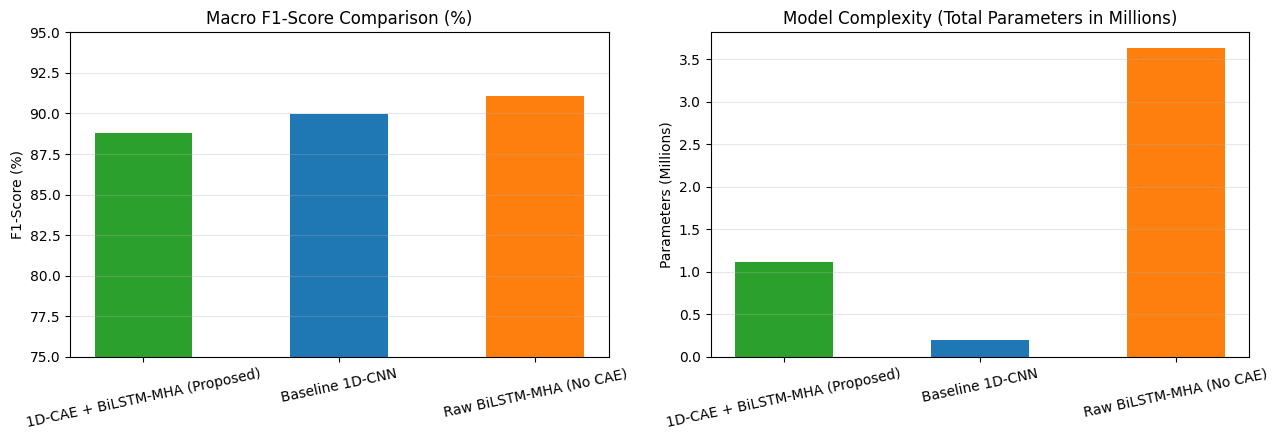

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

tf.random.set_seed(42)
np.random.seed(42)

# 1. التأكد من تحميل البيانات الخام والموديلات المحفوظة
if 'X_train_3d' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    def find_file(filename, search_path='/content/drive/MyDrive'):
        for root, dirs, files in os.walk(search_path):
            if filename in files:
                return os.path.join(root, filename)
        return None

    train_df = pd.read_csv(find_file('mitbih_train.csv'), header=None).replace([np.inf, -np.inf], np.nan).dropna()
    test_df  = pd.read_csv(find_file('mitbih_test.csv'), header=None).replace([np.inf, -np.inf], np.nan).dropna()

    X_train_full = train_df.iloc[:, :-1].values.astype(np.float32)
    y_train_full = train_df.iloc[:, -1].values.astype(np.int32)
    X_test = test_df.iloc[:, :-1].values.astype(np.float32)
    y_test = test_df.iloc[:, -1].values.astype(np.int32)

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.10, random_state=42, stratify=y_train_full
    )

    X_train_3d = np.expand_dims(X_train, axis=-1)
    X_val_3d   = np.expand_dims(X_val, axis=-1)
    X_test_3d  = np.expand_dims(X_test, axis=-1)

def evaluate_model_metrics(y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred) * 100.0
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0) * 100.0
    sens = recall_score(y_true, y_pred, average='macro', zero_division=0) * 100.0
    f1   = f1_score(y_true, y_pred, average='macro', zero_division=0) * 100.0
    cm   = confusion_matrix(y_true, y_pred)
    specs = []
    for i in range(5):
        tn = np.sum(cm) - (np.sum(cm[i, :]) + np.sum(cm[:, i]) - cm[i, i])
        fp = np.sum(cm[:, i]) - cm[i, i]
        specs.append(tn / (tn + fp))
    spec = np.mean(specs) * 100.0
    return acc, prec, sens, spec, f1

results_comparison = {}

# ==========================================================
# النموذج 1: المعمارية المقترحة الكاملة (1D-CAE + BiLSTM-MHA)
# ==========================================================
saved_encoder = tf.keras.models.load_model('/content/drive/MyDrive/cae_encoder.keras')
saved_clf     = tf.keras.models.load_model('/content/drive/MyDrive/bilstm_mha_best.keras')

t0 = time.time()
enc_test = saved_encoder.predict(X_test_3d, batch_size=256, verbose=0)
probs_proposed = saved_clf.predict(np.expand_dims(enc_test, -1), batch_size=256, verbose=0)
time_proposed_ms = ((time.time() - t0) / len(X_test_3d)) * 1000.0

y_pred_proposed = np.argmax(probs_proposed, axis=1)
params_proposed = saved_encoder.count_params() + saved_clf.count_params()
results_comparison['1D-CAE + BiLSTM-MHA (Proposed)'] = (
    *evaluate_model_metrics(y_test, y_pred_proposed), params_proposed, time_proposed_ms
)

# ==========================================================
# النموذج 2: Baseline 1D-CNN (بدون BiLSTM وبدون Attention)
# ==========================================================
print("\nTraining Model 2: Baseline 1D-CNN...")
cnn_baseline = models.Sequential([
    layers.Input(shape=(187, 1)),
    layers.Conv1D(64, kernel_size=3, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, kernel_size=3, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(5, activation='softmax')
], name="Baseline_1D_CNN")

cnn_baseline.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_baseline.fit(
    X_train_3d, y_train, epochs=35, batch_size=128, validation_data=(X_val_3d, y_val),
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)],
    verbose=0
)

t0 = time.time()
probs_cnn = cnn_baseline.predict(X_test_3d, batch_size=256, verbose=0)
time_cnn_ms = ((time.time() - t0) / len(X_test_3d)) * 1000.0
y_pred_cnn = np.argmax(probs_cnn, axis=1)
results_comparison['Baseline 1D-CNN'] = (
    *evaluate_model_metrics(y_test, y_pred_cnn), cnn_baseline.count_params(), time_cnn_ms
)
print("Baseline 1D-CNN finished!")

# ==========================================================
# النموذج 3: Raw BiLSTM + Multi-Head Attention (بدون 1D-CAE)
# ==========================================================
print("\nTraining Model 3: Raw BiLSTM-MHA (No Autoencoder)...")
raw_in = layers.Input(shape=(187, 1))
x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(raw_in)
x = layers.Dropout(0.3)(x)
x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
x = layers.Dropout(0.3)(x)
attn = layers.MultiHeadAttention(num_heads=8, key_dim=64)(x, x)
x = layers.LayerNormalization()(layers.Add()([x, attn]))
x = layers.Flatten()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.1)(x)
x = layers.Dense(64, activation='relu')(x)
raw_out = layers.Dense(5, activation='softmax')(x)

raw_bilstm_mha = models.Model(raw_in, raw_out, name="Raw_BiLSTM_MHA")
raw_bilstm_mha.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
raw_bilstm_mha.fit(
    X_train_3d, y_train, epochs=30, batch_size=128, validation_data=(X_val_3d, y_val),
    callbacks=[
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    ],
    verbose=1
)

t0 = time.time()
probs_raw = raw_bilstm_mha.predict(X_test_3d, batch_size=256, verbose=0)
time_raw_ms = ((time.time() - t0) / len(X_test_3d)) * 1000.0
y_pred_raw = np.argmax(probs_raw, axis=1)
results_comparison['Raw BiLSTM-MHA (No CAE)'] = (
    *evaluate_model_metrics(y_test, y_pred_raw), raw_bilstm_mha.count_params(), time_raw_ms
)

# ==========================================================
# طباعة جدول المقارنة الشامل ورسم بياني للتقرير
# ==========================================================
print("\n" + "="*98)
print("                    Architectural Comparison & Ablation Study (MIT-BIH Test Set)")
print("="*98)
print(f"{'Model Architecture':<32} | {'Acc%':<6} | {'Prec%':<6} | {'Sens%':<6} | {'Spec%':<6} | {'F1%':<6} | {'Params':<10} | {'ms/beat':<7}")
print("-"*98)
for name, vals in results_comparison.items():
    acc, prec, sens, spec, f1, params, ms = vals
    print(f"{name:<32} | {acc:<6.2f} | {prec:<6.2f} | {sens:<6.2f} | {spec:<6.2f} | {f1:<6.2f} | {params:<10,} | {ms:<7.4f}")
print("="*98)

# رسم بياني للمقارنة (جاهز للبرزنتيشن)
models_list = list(results_comparison.keys())
f1_scores   = [results_comparison[m][4] for m in models_list]
params_m    = [results_comparison[m][5] / 1e6 for m in models_list]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = ['#2ca02c', '#1f77b4', '#ff7f0e']

axes[0].bar(models_list, f1_scores, color=colors, width=0.5)
axes[0].set_title('Macro F1-Score Comparison (%)')
axes[0].set_ylabel('F1-Score (%)')
axes[0].set_ylim(75, 95)
axes[0].tick_params(axis='x', rotation=12)
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(models_list, params_m, color=colors, width=0.5)
axes[1].set_title('Model Complexity (Total Parameters in Millions)')
axes[1].set_ylabel('Parameters (Millions)')
axes[1].tick_params(axis='x', rotation=12)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Found PTB Normal:   /content/drive/MyDrive/MIT-BIH Arrhythmia/ptbdb_normal.csv
Found PTB Abnormal: /content/drive/MyDrive/MIT-BIH Arrhythmia/ptbdb_abnormal.csv

Total PTB Dataset Shape: (14552, 187, 1) | Normal (0): 4046, Abnormal (1): 10506

   Zero-Shot CAE Generalization on PTB Dataset
Compression Ratio (CR) : 5.84
RMSE (Unseen PTB Data) : 0.0348
PRD (%)                : 12.55%
Quality Score (QS)     : 0.4657

PTB Splits -> Train: (10476, 32, 1), Val: (1165, 32, 1), Test: (2911, 32, 1)
Epoch 1/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.7004 - loss: 0.6346 - val_accuracy: 0.7219 - val_loss: 0.5686 - learning_rate: 0.0010
Epoch 2/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.7169 - loss: 0.5574 - val_accuracy: 0.7408 - val_loss: 0.5260 - learning_rate: 0.0010
Epoch 3/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7446 - loss: 0.4981 - val_accuracy: 0.7639 - val_loss: 0.4686 - learning_rate: 0.0010
Epoch 4/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms

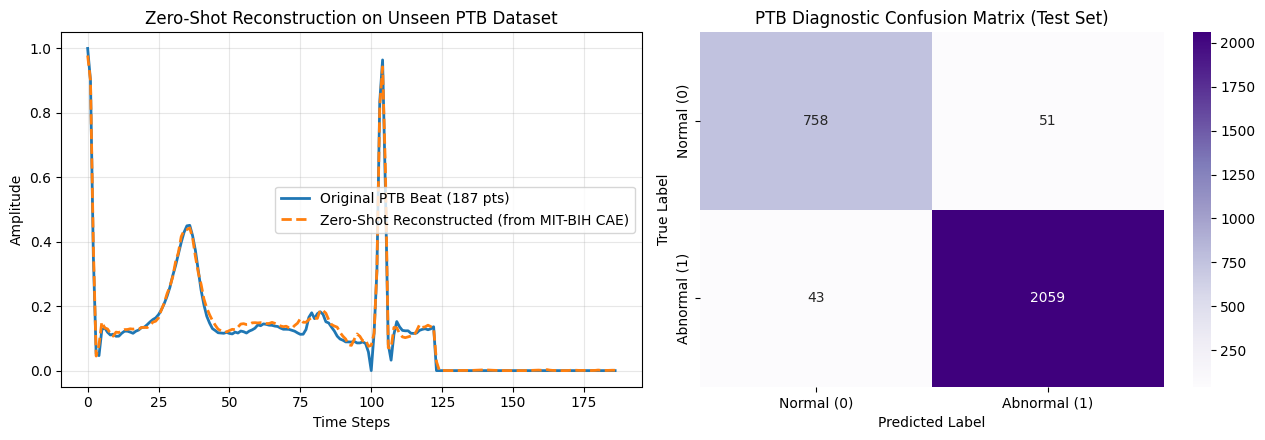

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

tf.random.set_seed(42)
np.random.seed(42)

# 1. ربط Google Drive والبحث عن ملفات PTB Diagnostic
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

def find_file(filename, search_path='/content/drive/MyDrive'):
    for root, dirs, files in os.walk(search_path):
        if filename in files:
            return os.path.join(root, filename)
    return None

ptb_norm_path = find_file('ptbdb_normal.csv')
ptb_abn_path  = find_file('ptbdb_abnormal.csv')

if ptb_norm_path is None or ptb_abn_path is None:
    raise FileNotFoundError("تأكد إن ملفات ptbdb_normal.csv و ptbdb_abnormal.csv مرفوعة جوا Google Drive!")

print("Found PTB Normal:  ", ptb_norm_path)
print("Found PTB Abnormal:", ptb_abn_path)

# قراءة ودمج وتنظيف داتا PTB
ptb_norm = pd.read_csv(ptb_norm_path, header=None).replace([np.inf, -np.inf], np.nan).dropna()
ptb_abn  = pd.read_csv(ptb_abn_path, header=None).replace([np.inf, -np.inf], np.nan).dropna()
ptb_df   = pd.concat([ptb_norm, ptb_abn], axis=0, ignore_index=True)

X_ptb = ptb_df.iloc[:, :-1].values.astype(np.float32)
y_ptb = ptb_df.iloc[:, -1].values.astype(np.int32)
X_ptb_3d = np.expand_dims(X_ptb, axis=-1)

print(f"\nTotal PTB Dataset Shape: {X_ptb_3d.shape} | Normal (0): {np.sum(y_ptb==0)}, Abnormal (1): {np.sum(y_ptb==1)}")

# ==========================================================
# 2. اختبار Zero-Shot Compression بالـ 1D-CAE المتدرب على MIT-BIH
# ==========================================================
cae_full    = tf.keras.models.load_model('/content/drive/MyDrive/cae_full.keras')
cae_encoder = tf.keras.models.load_model('/content/drive/MyDrive/cae_encoder.keras')

X_ptb_recon = cae_full.predict(X_ptb_3d, batch_size=256, verbose=0).squeeze()
cr_ptb   = 187.0 / 32.0
rmse_ptb = np.sqrt(np.mean((X_ptb - X_ptb_recon) ** 2))
prd_ptb  = (np.sqrt(np.sum((X_ptb - X_ptb_recon) ** 2)) / np.sqrt(np.sum(X_ptb ** 2))) * 100.0
qs_ptb   = cr_ptb / prd_ptb

print("\n" + "="*55)
print("   Zero-Shot CAE Generalization on PTB Dataset")
print("="*55)
print(f"Compression Ratio (CR) : {cr_ptb:.2f}")
print(f"RMSE (Unseen PTB Data) : {rmse_ptb:.4f}")
print(f"PRD (%)                : {prd_ptb:.2f}%")
print(f"Quality Score (QS)     : {qs_ptb:.4f}")
print("="*55)

# ==========================================================
# 3. استخراج الميزات المضغوطة (32-dim) وتقسيم PTB (Train / Val / Test)
# ==========================================================
X_ptb_encoded = np.expand_dims(cae_encoder.predict(X_ptb_3d, batch_size=256, verbose=0), axis=-1)

X_ptb_train_full, X_ptb_test, y_ptb_train_full, y_ptb_test = train_test_split(
    X_ptb_encoded, y_ptb, test_size=0.20, random_state=42, stratify=y_ptb
)
X_ptb_train, X_ptb_val, y_ptb_train, y_ptb_val = train_test_split(
    X_ptb_train_full, y_ptb_train_full, test_size=0.10, random_state=42, stratify=y_ptb_train_full
)

print(f"\nPTB Splits -> Train: {X_ptb_train.shape}, Val: {X_ptb_val.shape}, Test: {X_ptb_test.shape}")

# ==========================================================
# 4. بناء وتدريب المصنف الهجين BiLSTM + Multi-Head Attention على PTB
# ==========================================================
def build_ptb_classifier(seq_len=32):
    inputs = layers.Input(shape=(seq_len, 1))
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(inputs)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
    x = layers.Dropout(0.3)(x)

    attn = layers.MultiHeadAttention(num_heads=8, key_dim=64)(x, x)
    x = layers.LayerNormalization()(layers.Add()([x, attn]))

    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.1)(x)
    x = layers.Dense(64, activation='relu')(x)
    outputs = layers.Dense(2, activation='softmax')(x)
    return models.Model(inputs, outputs, name="PTB_BiLSTM_MHA")

ptb_model = build_ptb_classifier(seq_len=32)
ptb_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_ptb = ptb_model.fit(
    X_ptb_train, y_ptb_train,
    epochs=60,
    batch_size=64,
    validation_data=(X_ptb_val, y_ptb_val),
    callbacks=[
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=0),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1)
    ],
    verbose=1
)

ptb_model.save('/content/drive/MyDrive/ptb_bilstm_mha.keras')

# ==========================================================
# 5. التقييم النهائي على PTB Test Set
# ==========================================================
y_ptb_probs = ptb_model.predict(X_ptb_test, batch_size=256, verbose=0)
y_ptb_pred  = np.argmax(y_ptb_probs, axis=1)

acc_p  = accuracy_score(y_ptb_test, y_ptb_pred) * 100.0
prec_p = precision_score(y_ptb_test, y_ptb_pred, zero_division=0) * 100.0
sens_p = recall_score(y_ptb_test, y_ptb_pred, zero_division=0) * 100.0
f1_p   = f1_score(y_ptb_test, y_ptb_pred, zero_division=0) * 100.0
auc_p  = roc_auc_score(y_ptb_test, y_ptb_probs[:, 1]) * 100.0

cm_p = confusion_matrix(y_ptb_test, y_ptb_pred)
tn, fp, fn, tp = cm_p.ravel()
spec_p = (tn / (tn + fp)) * 100.0

print("\n" + "="*55)
print("   Bonus: Cross-Dataset Performance on PTB Diagnostic")
print("="*55)
print(f"Accuracy (%)             : {acc_p:.2f}%")
print(f"Precision (%)            : {prec_p:.2f}%")
print(f"Sensitivity / Recall (%) : {sens_p:.2f}%")
print(f"Specificity (%)          : {spec_p:.2f}%")
print(f"F1-Score (%)             : {f1_p:.2f}%")
print(f"ROC-AUC (%)              : {auc_p:.2f}%")
print("="*55)

# رسم إعادة البناء ومصفوفة الارتباك لداتا PTB
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(X_ptb[0], label='Original PTB Beat (187 pts)', linewidth=2)
axes[0].plot(X_ptb_recon[0], '--', label='Zero-Shot Reconstructed (from MIT-BIH CAE)', linewidth=2)
axes[0].set_title('Zero-Shot Reconstruction on Unseen PTB Dataset')
axes[0].set_xlabel('Time Steps')
axes[0].set_ylabel('Amplitude')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

sns.heatmap(cm_p, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Normal (0)', 'Abnormal (1)'],
            yticklabels=['Normal (0)', 'Abnormal (1)'], ax=axes[1])
axes[1].set_title('PTB Diagnostic Confusion Matrix (Test Set)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [ ]:
!pip install -q streamlit
!wget -q -O - ipv4.icanhazip.com  # انسخ رقم الـ IP اللي هيطبع هنا
!streamlit run /content/drive/MyDrive/app.py & npx localtunnel --port 8501

34.126.164.197
⠙⠹Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: /content/drive/MyDrive/app.py
⠸⠼Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) ^C


In [ ]:
import os, pandas as pd
from google.colab import drive

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

def find_file(filename, search_path='/content/drive/MyDrive'):
    for root, dirs, files in os.walk(search_path):
        if filename in files:
            return os.path.join(root, filename)
    return None

test_df = pd.read_csv(find_file('mitbih_test.csv'), header=None)
demo_mit = pd.concat([test_df[test_df.iloc[:, -1] == c].head(10) for c in range(5)])
demo_mit.to_csv('/content/drive/MyDrive/mitbih_demo_samples.csv', index=False, header=False)

ptb_n = pd.read_csv(find_file('ptbdb_normal.csv'), header=None).head(10)
ptb_a = pd.read_csv(find_file('ptbdb_abnormal.csv'), header=None).head(10)
demo_ptb = pd.concat([ptb_n, ptb_a])
demo_ptb.to_csv('/content/drive/MyDrive/ptb_demo_samples.csv', index=False, header=False)

print("Demo sample files created successfully on Drive!")

Demo sample files created successfully on Drive!


In [ ]:
%%writefile /content/drive/MyDrive/app.py
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st
import tensorflow as tf

st.set_page_config(page_title="ECG Arrhythmia AI Classifier", page_icon="🫀", layout="wide")

# تحديد مسار الملفات تلقائياً (سواء جوا Colab Drive أو على اللابتوب)
BASE_DIR = "/content/drive/MyDrive" if os.path.exists("/content/drive/MyDrive/cae_full.keras") else "."

@st.cache_resource
def load_models():
    cae_full = tf.keras.models.load_model(os.path.join(BASE_DIR, "cae_full.keras"))
    enc_path = os.path.join(BASE_DIR, "cae_encoder.keras")
    cae_encoder = tf.keras.models.load_model(enc_path) if os.path.exists(enc_path) else cae_full.get_layer("CAE_Encoder")

    clf_base = tf.keras.models.load_model(os.path.join(BASE_DIR, "bilstm_mha_best.keras"))
    clf_opt  = tf.keras.models.load_model(os.path.join(BASE_DIR, "bilstm_mha_optimized.keras"))
    ptb_path = os.path.join(BASE_DIR, "ptb_bilstm_mha.keras")
    clf_ptb  = tf.keras.models.load_model(ptb_path) if os.path.exists(ptb_path) else None
    return cae_full, cae_encoder, clf_base, clf_opt, clf_ptb

st.title("🫀 ECG Heartbeat Compression & Arrhythmia Classification")
st.markdown(
    "**Two-Stage Deep Learning Pipeline:** `1D-Convolutional Autoencoder (187 → 32)` + "
    "`Stacked BiLSTM & Multi-Head Self-Attention` *(Degachi et al., IEEE Access 2025)*"
)
st.divider()

cae_full, cae_encoder, clf_base, clf_opt, clf_ptb = load_models()

st.sidebar.header("⚙️ Configuration")
dataset_mode = st.sidebar.radio(
    "Select Task / Dataset:",
    ["MIT-BIH Arrhythmia (5 Classes)", "PTB Diagnostic (Bonus: Normal vs MI)"]
)

if dataset_mode == "MIT-BIH Arrhythmia (5 Classes)":
    model_choice = st.sidebar.selectbox(
        "Select Classifier Version:",
        ["Optimized BiLSTM-MHA (Class-Weighted)", "Baseline BiLSTM-MHA (Paper Reproduction)"]
    )
    active_clf = clf_opt if "Optimized" in model_choice else clf_base
    class_names = [
        "N (Normal Beat)",
        "SVEB (Supraventricular Ectopic)",
        "VEB (Ventricular Ectopic)",
        "F (Fusion Beat)",
        "Q (Unknown / Paced Beat)"
    ]
    default_csv = os.path.join(BASE_DIR, "mitbih_demo_samples.csv")
else:
    if clf_ptb is None:
        st.sidebar.error("ptb_bilstm_mha.keras not found!")
        st.stop()
    active_clf = clf_ptb
    class_names = ["Normal Heartbeat (0)", "Abnormal / Myocardial Infarction (1)"]
    default_csv = os.path.join(BASE_DIR, "ptb_demo_samples.csv")

st.sidebar.divider()
st.sidebar.subheader("📂 Input Heartbeat Source")
uploaded_file = st.sidebar.file_uploader("Upload ECG CSV (187 or 188 cols)", type=["csv"])

if uploaded_file is not None:
    df = pd.read_csv(uploaded_file, header=None)
elif os.path.exists(default_csv):
    df = pd.read_csv(default_csv, header=None)
    st.sidebar.success(f"Loaded demo samples ({len(df)} beats)")
else:
    st.warning("Please upload a CSV file containing ECG beats.")
    st.stop()

beat_idx = st.sidebar.slider("Select Heartbeat Sample Index:", 0, len(df) - 1, 0)
row = df.iloc[beat_idx].values.astype(np.float32)

signal = row[:187]
true_label = int(row[187]) if len(row) >= 188 else None

signal_3d = signal.reshape(1, 187, 1)
t0 = time.time()
reconstructed = cae_full.predict(signal_3d, verbose=0).squeeze()
latent_vec = cae_encoder.predict(signal_3d, verbose=0)
probs = active_clf.predict(latent_vec.reshape(1, 32, 1), verbose=0).squeeze()
infer_ms = (time.time() - t0) * 1000.0

pred_idx = int(np.argmax(probs))
confidence = float(probs[pred_idx]) * 100.0

cr = 187.0 / 32.0
rmse = float(np.sqrt(np.mean((signal - reconstructed) ** 2)))
prd = float((np.sqrt(np.sum((signal - reconstructed) ** 2)) / (np.sqrt(np.sum(signal ** 2)) + 1e-8)) * 100.0)

col_m1, col_m2, col_m3, col_m4 = st.columns(4)
col_m1.metric("Predicted Diagnosis", class_names[pred_idx].split(" ")[0], f"{confidence:.1f}% Confidence")
if true_label is not None and true_label < len(class_names):
    match_text = "✅ Correct Match" if pred_idx == true_label else "❌ Mismatch"
    col_m2.metric("Ground Truth Label", class_names[true_label].split(" ")[0], match_text)
else:
    col_m2.metric("Ground Truth Label", "N/A", "Unlabeled Input")
col_m3.metric("Compression Ratio", f"{cr:.2f}x", "187 → 32 features")
col_m4.metric("Reconstruction Error", f"RMSE: {rmse:.4f}", f"PRD: {prd:.2f}% | {infer_ms:.1f} ms")

st.divider()

col_left, col_right = st.columns([1.4, 1])

with col_left:
    st.subheader("📈 Stage 1: 1D-CAE Signal Compression & Reconstruction")
    fig1, ax1 = plt.subplots(figsize=(8, 3.6))
    ax1.plot(signal, label="Original ECG Signal (187 pts)", color="#1f77b4", linewidth=2)
    ax1.plot(reconstructed, "--", label="Reconstructed from 32-dim Latent", color="#ff7f0e", linewidth=2)
    ax1.set_xlabel("Time Steps (Samples)")
    ax1.set_ylabel("Normalized Amplitude")
    ax1.legend(loc="upper right")
    ax1.grid(True, alpha=0.3)
    st.pyplot(fig1)

    with st.expander("🔍 View Compressed 32-Dimensional Bottleneck Vector"):
        fig_lat, ax_lat = plt.subplots(figsize=(8, 2))
        ax_lat.bar(range(32), latent_vec.squeeze(), color="#2ca02c")
        ax_lat.set_xlabel("Latent Feature Index (0 - 31)")
        ax_lat.set_ylabel("Activation")
        ax_lat.grid(axis="y", alpha=0.3)
        st.pyplot(fig_lat)

with col_right:
    st.subheader("🧠 Stage 2: BiLSTM-MHA Class Probabilities")
    fig2, ax2 = plt.subplots(figsize=(6, 3.6))
    short_names = [c.split(" (")[0] for c in class_names]
    bar_colors = ["#2ca02c" if i == pred_idx else "#aec7e8" for i in range(len(class_names))]
    bars = ax2.barh(short_names[::-1], (probs * 100)[::-1], color=bar_colors[::-1])
    ax2.set_xlim(0, 108)
    ax2.set_xlabel("Prediction Probability (%)")
    ax2.grid(axis="x", alpha=0.3)
    for bar in bars:
        w = bar.get_width()
        ax2.text(w + 1.5, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=9)
    st.pyplot(fig2)

    if pred_idx == 0:
        st.success(f"**Result:** {class_names[pred_idx]} — Normal cardiac rhythm detected.")
    else:
        st.warning(f"**Alert:** {class_names[pred_idx]} — Arrhythmia / abnormality detected.")

Writing /content/drive/MyDrive/app.py


In [ ]:
!pip install -q streamlit
!wget -q -O - ipv4.icanhazip.com
!streamlit run /content/drive/MyDrive/app.py --server.port 8501 & npx --yes localtunnel --port 8501

34.126.164.197
⠙⠹

⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋2026-11-23 23:40:07.372 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.126.164.197:8501

  Stopping...
^C


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!streamlit run /content/drive/MyDrive/app.py --server.port 8501 & ./cloudflared tunnel --url http://localhost:8501

2026-11-23T23:43:12Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-23T23:43:12Z INF Requesting new quick Tunnel on trycloudflare.com...


2026-11-23 23:43:16.041 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.126.164.197:8501

2026-11-23T23:43:17Z INF +------------------------------------------------------------